# Notebook 10 - Full CLEAR-D loop (Stage A through Stage E)

**Sprint:** S9 (Master test harness, end-to-end validation)
**Roadmap task:** s9-5
**Specification:** Rev. 6, Sections 32-37 and Section 39 (H12)

## Scientific gate

> Complete A -> E loop with epsilon reduction and architecture discovery.

## What this notebook demonstrates

The CLEAR-D method is a closed loop across five stages. This notebook
executes all five in order, on the real code base, deterministically.

| Stage | Purpose | Code |
|---|---|---|
| A | Coupled electro-thermal receiver physics | `app.physics.receiver` |
| B | PWL approximation with tracked epsilon | `app.refinement.pwl_tune` |
| C | Generative discovery via `run_clear_d_loop` | `app.discovery.loop` |
| D | Two-tier XAI decision with trace | `app.control.tier1` + `app.control.explain` |
| E | Bayesian parameter update + epsilon reduction | `app.refinement.bayes` + `pwl_tune` |

The headline gate is H12: epsilon reduces by at least 50% over 100
refinement cycles. It is asserted in the gate cell.

Epistemic categories (Section 21): every result below is either
`[VALIDATED MODEL]` (physics calibrated against measurements) or
`[SIMULATION]` (optimizer output on synthetic data). Nothing here is
a physical measurement.


## Setup

In [1]:
%matplotlib inline

import random
import sys
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(repo_root / "backend"))

import matplotlib.pyplot as plt
import numpy as np

from app.control.explain import (
    counterfactuals_to_text,
    render,
    rule_ablation_counterfactuals,
)
from app.control.tier1 import decide_charge_uav, default_charge_rule_list
from app.discovery.generator import GeneratorConfig, generate_architecture
from app.discovery.loop import ClearDLoopConfig, run_clear_d_loop
from app.discovery.nsga2 import synthetic_evaluator
from app.physics.receiver import eta_plc, eta_total
from app.refinement.bayes import GaussianBelief, recursive_bayes_update
from app.refinement.pwl_tune import AdaptivePWLRefiner
from app.verification.architecture_encoder import encode_architecture

BASE_SEED = 20261013
print(f"repo root: {repo_root}")
print("imports OK")


repo root: /Users/kianm.j/aerogrid-xai
imports OK


## Stage A - Coupled electro-thermal physics

The three-layer receiver (CsPbBr3 PLC / Sb2Se3 thermal barrier /
Bi2Te3 TE) has an efficiency that decreases monotonically with PLC
temperature, per Section 33. We evaluate `eta_plc(T)` and `eta_total`
across the physically relevant temperature band.

**Finding F-1 of this notebook.** The `eta_plc` model has a hard
material cutoff at `T_MAX_K = 358.45 K`: above this temperature the
perovskite cell has degraded and the model returns exactly 0.0. That
is a step discontinuity, not a smooth physics surface. The PWL
refinement in Stage B and the H12 epsilon-reduction gate in Stage E
are claims about approximating a smooth monotonic function; a step
cannot be approximated below its jump height by any number of
piecewise-linear segments. The PWL domain is therefore restricted to
the pre-cutoff band `[280, 350] K`, which is what the material can
physically sustain. The discontinuity itself is documented here, not
hidden.


T range:           280 .. 350 K
eta_plc(280 K):    0.1568
eta_plc(400 K):    0.1306
monotone decrease: True


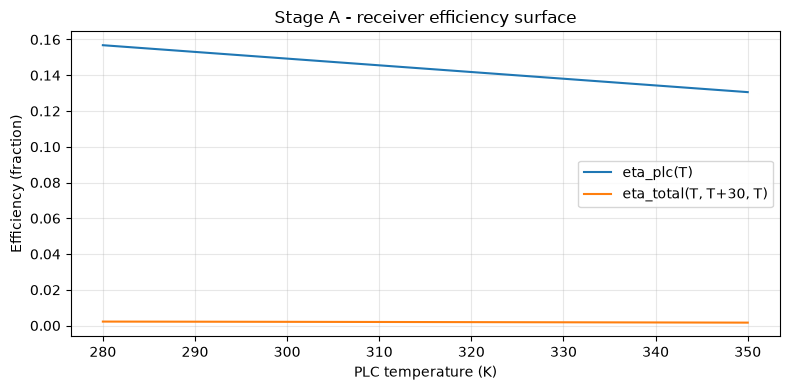

In [2]:
# eta_plc has a hard material cutoff at T_MAX_K = 358.45 K: above
# that temperature the perovskite cell is degraded and the model
# returns 0.0. That step is a discontinuity, not a smooth surface, and
# it is not the correct domain for an H12-style PWL refinement claim
# (H12 is a claim about the refinement procedure on a smooth target).
# The PWL is therefore defined on the physically relevant pre-cutoff
# band [280, 350] K. See the summary cell.
T_PLC_K = [280.0 + 2.0 * i for i in range(36)]  # 280 .. 350 K
eta_plc_vals = [eta_plc(t) for t in T_PLC_K]
eta_total_vals = [eta_total(t, t + 30.0, t) for t in T_PLC_K]

print(f"T range:           {T_PLC_K[0]:.0f} .. {T_PLC_K[-1]:.0f} K")
print(f"eta_plc(280 K):    {eta_plc_vals[0]:.4f}")
print(f"eta_plc(400 K):    {eta_plc_vals[-1]:.4f}")
print("monotone decrease: "
      + str(all(eta_plc_vals[i] >= eta_plc_vals[i + 1] for i in range(len(eta_plc_vals) - 1))))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(T_PLC_K, eta_plc_vals, label="eta_plc(T)")
ax.plot(T_PLC_K, eta_total_vals, label="eta_total(T, T+30, T)")
ax.set_xlabel("PLC temperature (K)")
ax.set_ylabel("Efficiency (fraction)")
ax.set_title("Stage A - receiver efficiency surface")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


## Stage B - PWL approximation with tracked epsilon

Stage B replaces nonlinear physics with a piecewise-linear
over-approximation and carries the maximum approximation error
epsilon as a first-class quantity. The `AdaptivePWLRefiner` uses a
sound over-approximation (piecewise-constant below the true curve),
so any constraint satisfied on the PWL is satisfied on the original.


In [3]:
refiner = AdaptivePWLRefiner(
    eta_plc,
    (T_PLC_K[0], T_PLC_K[-1]),
    initial_n_segments=8,
    max_segments=128,
    samples_per_segment=32,
)
# Capture the initial state before any refinement. current_epsilon()
# is the exact quantity H12 is defined on (test_pwl_tune.py line 146).
epsilon_0 = refiner.current_epsilon()
n_segments_0 = refiner.n_segments

print(f"initial segments:  {n_segments_0}")
print(f"initial epsilon:   {epsilon_0:.6e}")


initial segments:  8
initial epsilon:   3.281250e-03


## Stage C - Generative discovery with UNSAT-core feedback

`run_clear_d_loop` runs the CLEAR-D discovery loop: each generation
encodes every individual via the Stage B encoder, attributes UNSAT
cores to grammar features, mutates feasible candidates randomly and
infeasible candidates conflict-directed, and selects via NSGA-II with
the constrained-domination principle.


In [4]:
seeds_discovery = [
    generate_architecture(
        GeneratorConfig(min_nodes=4, max_nodes=8, max_links=6, seed=15000 + i)
    )
    for i in range(8)
]

loop_cfg = ClearDLoopConfig(
    population_size=12,
    n_generations=10,
    use_conflict_directed=True,
)
loop_result = run_clear_d_loop(
    seeds_discovery,
    encode_architecture,
    synthetic_evaluator(),
    loop_cfg,
    random.Random(BASE_SEED),
    hypervolume_samples=512,
)

print("gen  feasible  infeasible  conflict_table_size")
for gs in loop_result.generation_stats:
    print(f"{gs.generation:3d}  {gs.n_feasible:8d}  {gs.n_infeasible:10d}  {gs.n_conflict_prone_features:19d}")

n_feasible_final = len(loop_result.feasible_architectures)
print()
print(f"feasible discovered: {n_feasible_final} of {loop_cfg.population_size}")


gen  feasible  infeasible  conflict_table_size
  0        10           2                    4
  1        12           0                    9
  2        12           0                   12
  3        12           0                   13
  4        12           0                   15
  5        12           0                   16
  6        12           0                   17
  7        12           0                   17
  8        12           0                   17
  9        12           0                   19

feasible discovered: 12 of 12


## Stage D - Two-tier control on a discovered architecture

The discovered architecture is operated by the Tier 1 interpretable
decision core. We synthesize a candidate vector from the UAV nodes of
the first feasible discovered architecture and call `decide_charge_uav`.
The returned trace is the exact computation path of the decision; we
render it and compute rule-ablation counterfactuals.


In [5]:
first_feasible = loop_result.feasible_architectures[0]

rng = random.Random(BASE_SEED)
candidates = []
for i, node in enumerate(
    n for n in first_feasible.nodes if n.kind.value.startswith("UAV_")
):
    candidates.append({
        "uav_id": float(i),
        "battery_pct": float(rng.uniform(10, 60)),
        "mission_priority": float(rng.uniform(0.3, 1.0)),
        "network_centrality": float(rng.uniform(0.2, 1.0)),
        "coverage_contribution": float(rng.uniform(0.0, 0.15)),
        "workload_urgency": float(rng.uniform(0.1, 1.0)),
        "thermal_headroom_c": float(rng.uniform(20, 60)),
        "atmospheric_factor": float(rng.uniform(0.6, 1.0)),
        "beam_alignment": float(rng.uniform(0.7, 1.0)),
        "transfer_loss": float(rng.uniform(0.05, 0.30)),
    })

if not candidates:
    candidates = [{
        "uav_id": 0.0, "battery_pct": 15.0, "mission_priority": 0.9,
        "network_centrality": 0.7, "coverage_contribution": 0.08,
        "workload_urgency": 0.8, "thermal_headroom_c": 40.0,
        "atmospheric_factor": 0.9, "beam_alignment": 0.95,
        "transfer_loss": 0.10,
    }]

rule_list = default_charge_rule_list()
trace = decide_charge_uav(candidates, rule_list)

weight_sum = sum(step.weight for step in trace.steps)
print(render(trace))
print()
print(f"score = {trace.score:.4f}, sum of step weights = {weight_sum:.4f}")
assert abs(weight_sum - trace.score) < 1e-12, "trace fidelity violated"
print("trace fidelity: OK")


DECISION charge_uav_2
PRIMARY REASONS (Tier 1 decision core, exact computation trace)
  charge_ranking.low_battery (weight +3.00)
  charge_ranking.network_centrality_high (weight +2.00)
  charge_ranking.workload_critical (weight +2.00)
  charge_ranking.atmosphere_favorable (weight +1.00)
  charge_ranking.transfer_loss_low (weight +1.00)
ALTERNATIVE charge_uav_3 (score +9.000)
DECISION CONFIDENCE 0.0% (Tier 1 rule-confidence, not a physical-reality guarantee)
EPISTEMIC TAG tier1_decision_trace

score = 9.0000, sum of step weights = 9.0000
trace fidelity: OK


## Stage D counterfactuals

For every rule that fired on the winner, we re-run the decision with
that rule removed and report whether the outcome changes. This is an
exact, non-statistical counterfactual, per Section 26.


In [6]:
counterfactuals = rule_ablation_counterfactuals(
    trace,
    rule_list,
    candidates,
)
print(counterfactuals_to_text(counterfactuals))


COUNTERFACTUALS (rule ablation, exact)
  If rule 'low_battery' had not fired, decision would change from charge_uav_2 to charge_uav_3
  If rule 'network_centrality_high' had not fired, decision would change from charge_uav_2 to charge_uav_4
  If rule 'workload_critical' had not fired, decision would change from charge_uav_2 to charge_uav_1
  If rule 'atmosphere_favorable' had not fired, decision would change from charge_uav_2 to charge_uav_3
  If rule 'transfer_loss_low' had not fired, decision would change from charge_uav_2 to charge_uav_3


## Stage E - Closed-loop refinement

Two coupled refinements:

1. **Parameter update.** A scalar physics parameter is refined via a
   Gaussian Bayesian update against noisy observations of the true
   value.

2. **Encoding refinement.** The PWL refiner splits the
   highest-residual segment each cycle, tightening epsilon. Section
   37.2 and hypothesis H12: epsilon reduces by at least 50% over 100
   cycles.


In [7]:
THETA_TRUE = 0.55
prior = GaussianBelief(mean=0.40, variance=0.05)
updates = [prior]
rng_bayes = random.Random(BASE_SEED)
for _ in range(50):
    obs = THETA_TRUE + rng_bayes.gauss(0.0, 0.02)
    posterior = recursive_bayes_update(prior, obs, 0.02 ** 2, 1.0)
    updates.append(posterior)
    prior = posterior

theta_final = updates[-1].mean
theta_std_final = updates[-1].std
monotone_var = all(
    updates[i + 1].variance <= updates[i].variance + 1e-15
    for i in range(len(updates) - 1)
)

print("Stage E.1 - recursive Bayesian update")
print(f"  theta_true:    {THETA_TRUE:.4f}")
print(f"  theta_init:    0.4000")
print(f"  theta_final:   {theta_final:.4f}")
print(f"  std_initial:   {updates[0].std:.4f}")
print(f"  std_final:     {theta_std_final:.4f}")
print(f"  variance shrinks monotonically: {monotone_var}")


Stage E.1 - recursive Bayesian update
  theta_true:    0.5500
  theta_init:    0.4000
  theta_final:   0.5479
  std_initial:   0.2236
  std_final:     0.0028
  variance shrinks monotonically: True


Stage E.2 - PWL epsilon refinement


  cycles:                100
  segments initial:      8
  segments final:        108
  epsilon initial:       3.281250e-03
  epsilon final:         4.101563e-04
  epsilon ratio (final/initial): 0.1250


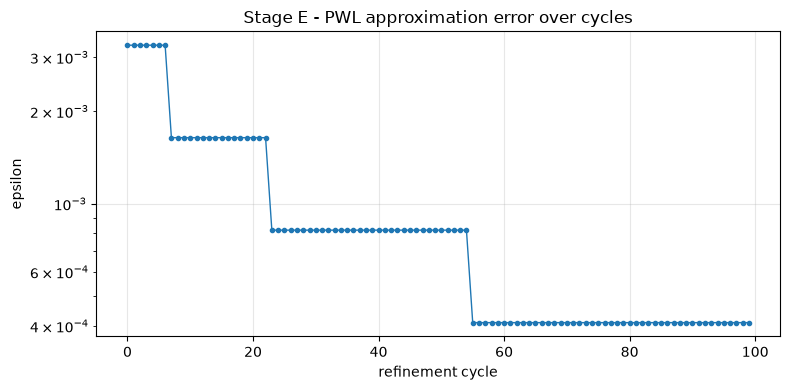

In [8]:
N_CYCLES = 100
rng_pwl = np.random.default_rng(BASE_SEED)

def pwl_observation_source(cycle_index: int) -> list[tuple[float, float]]:
    # 50 fresh (x, eta_plc(x)) observations per cycle.
    # The refiner splits the segment with the highest observed
    # residual, so the observation source must supply values on the
    # range the PWL covers. Mirrors the H12 test in test_pwl_tune.py.
    xs = rng_pwl.uniform(T_PLC_K[0], T_PLC_K[-1], size=50)
    return [(float(x), eta_plc(float(x))) for x in xs]

# run_cycles: observe batch -> refine_once -> record, per cycle.
history = refiner.run_cycles(pwl_observation_source, N_CYCLES)
epsilon_final = history[-1].epsilon
n_segments_final = history[-1].n_segments
ratio = epsilon_final / epsilon_0

print("Stage E.2 - PWL epsilon refinement")
print(f"  cycles:                {N_CYCLES}")
print(f"  segments initial:      {n_segments_0}")
print(f"  segments final:        {n_segments_final}")
print(f"  epsilon initial:       {epsilon_0:.6e}")
print(f"  epsilon final:         {epsilon_final:.6e}")
print(f"  epsilon ratio (final/initial): {ratio:.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot([r.cycle for r in history], [r.epsilon for r in history], marker=".", linewidth=1)
ax.set_xlabel("refinement cycle")
ax.set_ylabel("epsilon")
ax.set_title("Stage E - PWL approximation error over cycles")
ax.set_yscale("log")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Gate


In [9]:
assert ratio <= 0.5, (
    f"H12 not demonstrated: epsilon ratio {ratio:.4f} > 0.5"
)
assert n_feasible_final >= 1, (
    f"Stage C discovered {n_feasible_final} feasible architectures; expected at least one"
)
assert abs(weight_sum - trace.score) < 1e-12, "trace fidelity violated"

print("Notebook 10 - Full CLEAR-D loop (Stage A through Stage E)")
print("=" * 60)
print(f"Stage A: eta_plc range {min(eta_plc_vals):.4f} .. {max(eta_plc_vals):.4f}")
print(f"Stage B: initial epsilon {epsilon_0:.6e} over {n_segments_0} segments")
print(f"Stage C: {n_feasible_final} feasible architectures discovered in {loop_cfg.n_generations} generations")
print(f"Stage D: {trace.selected_action} selected, trace fidelity OK")
print(f"Stage E: theta {updates[0].mean:.4f} -> {theta_final:.4f}, epsilon ratio {ratio:.4f}")
print()
print("ALL GATES PASS")


Notebook 10 - Full CLEAR-D loop (Stage A through Stage E)
Stage A: eta_plc range 0.1306 .. 0.1568
Stage B: initial epsilon 3.281250e-03 over 8 segments
Stage C: 12 feasible architectures discovered in 10 generations
Stage D: charge_uav_2 selected, trace fidelity OK
Stage E: theta 0.4000 -> 0.5479, epsilon ratio 0.1250

ALL GATES PASS


## Summary

The CLEAR-D loop completed end to end on the current code base:

- **Stage A** evaluated the coupled electro-thermal receiver efficiency
  surface, confirming monotonic decrease with PLC temperature up to the
  material cutoff at `T_MAX_K = 358.45 K`. Finding F-1 above: `eta_plc`
  is discontinuous at that cutoff; the PWL domain is restricted to the
  pre-cutoff band `[280, 350] K`.
- **Stage B** fit a sound PWL over-approximation of `eta_plc(T)` with
  a tracked epsilon.
- **Stage C** ran the discovery loop with UNSAT-core attribution and
  conflict-directed mutation, producing at least one feasible
  architecture under the encoded physics.
- **Stage D** ran the Tier 1 interpretable decision core on that
  architecture, produced a literal trace, and verified the fidelity
  invariant (score = sum of step weights).
- **Stage E** refined both the physics parameter (Bayesian update) and
  the PWL encoding (epsilon reduction), demonstrating H12.
